# Concurrency prediction based on actual and/or predicted schedules

In [1]:
# Import required libraries
import h2o
from h2o.automl import H2OAutoML
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import warnings

warnings.filterwarnings("ignore")

# Initialize H2O
print("Initializing H2O...")
h2o.init(max_mem_size="4G")  # Adjust based on available memory
print("H2O initialized successfully!")

Initializing H2O...
Checking whether there is an H2O instance running at http://localhost:54321. connected.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html
 connected.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,3 hours 8 mins
H2O_cluster_timezone:,Europe/Oslo
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,6 months and 1 day
H2O_cluster_name:,H2O_from_python_kristsey_9mzclv
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,11.76 Gb
H2O_cluster_total_cores:,24
H2O_cluster_allowed_cores:,24
H2O_cluster_status:,"locked, healthy"


H2O initialized successfully!


In [2]:
# Load the historical flights dataset
print("Loading historical schedule data")
scheduled_path = "/home/kristsey/AvinorHackathon/data/concurrency/scheduled_concurrency.csv"
actual_path = (
    "/home/kristsey/AvinorHackathon/data/concurrency/actual_concurrency.csv"
)
predicted_path= (
    "/home/kristsey/AvinorHackathon/data/concurrency/predicted_concurrency.csv"
)

# Combine chunks
df_scheduled = pd.read_csv(scheduled_path) # Use predicted for testing
df_actual = pd.read_csv(actual_path)
df_predicted = pd.read_csv(predicted_path)
print(len(df_scheduled), len(df_actual),len(df_predicted))
print(df_scheduled["date"].min(),df_actual["date"].min(),df_predicted["date"].min())
print(df_scheduled["date"].max(),df_actual["date"].max(),df_predicted["date"].max())

# Display basic information about the dataset
print("\nDataset Info:")
print(df_scheduled.info())
print("\nFirst few rows:")
print(df_scheduled.head())
print("\nDataset statistics:")
print(df_scheduled.describe())

# Create the main dataframe from scheduled/predicted data and set target values to actual values
df = df_scheduled[["airport_group","date","hour"]].copy()
df[["scheduled_concurrency","scheduled_number_of_flights","scheduled_overlapping_time_minutes","scheduled_is_concurrency"]] = df_scheduled[["concurrency","number_of_flights","overlapping_time_minutes","is_concurrency"]]
df[["predicted_concurrency","predicted_number_of_flights","predicted_overlapping_time_minutes","predicted_is_concurrency"]] = df_scheduled[["concurrency","number_of_flights","overlapping_time_minutes","is_concurrency"]]

df["is_concurrency"] = df_actual["is_concurrency"] # set target values to actual values

print(f"\nTarget variable distribution:")
print(df["is_concurrency"].value_counts())
print(f"Target variable type: {df['is_concurrency'].dtype}")

Loading historical schedule data
465192 465192 465192
2018-01-01 2018-01-01 2018-01-01
2025-07-31 2025-07-31 2025-07-31

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 465192 entries, 0 to 465191
Data columns (total 7 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   airport_group             465192 non-null  object 
 1   date                      465192 non-null  object 
 2   hour                      465192 non-null  int64  
 3   concurrency               465192 non-null  int64  
 4   number_of_flights         465192 non-null  int64  
 5   overlapping_time_minutes  465192 non-null  float64
 6   is_concurrency            465192 non-null  int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 24.8+ MB
None

First few rows:
  airport_group        date  hour  concurrency  number_of_flights  \
0             A  2018-01-01     0            0                  0   
1             B  2018-01-01 

In [3]:
test_path_schedule= "/home/kristsey/AvinorHackathon/data/concurrency/scheduled_concurrency_october_24.csv"
test_path_predicted= "/home/kristsey/AvinorHackathon/data/concurrency/predicted_concurrency_october_24.csv"
test_path_actual= "/home/kristsey/AvinorHackathon/data/concurrency/actual_concurrency_october_24.csv"


df_schedule_test = pd.read_csv(test_path_schedule) # retrieve test dataset for testing
df_predicted_test = pd.read_csv(test_path_predicted) # retrieve test dataset for testing
df_actual_test = pd.read_csv(test_path_actual)

print(len(df_schedule_test),len(df_predicted_test), len(df_actual_test))

# Create the main dataframe from scheduled/predicted data and set target values to actual values
df_test = df_schedule_test[["airport_group","date","hour"]].copy()
df_test[["scheduled_concurrency","scheduled_number_of_flights","scheduled_overlapping_time_minutes","scheduled_is_concurrency"]] = df_schedule_test[["concurrency","number_of_flights","overlapping_time_minutes","is_concurrency"]]
df_test[["predicted_concurrency","predicted_number_of_flights","predicted_overlapping_time_minutes","predicted_is_concurrency"]] = df_predicted_test[["concurrency","number_of_flights","overlapping_time_minutes","is_concurrency"]]

df_test["is_concurrency"] = df_actual_test["is_concurrency"] # set target values to actual values

print(f"\nTarget variable distribution:")
print(df_test["is_concurrency"].value_counts())
print(f"Target variable type: {df_test['is_concurrency'].dtype}")

5208 5208 5208

Target variable distribution:
is_concurrency
0    3755
1    1453
Name: count, dtype: int64
Target variable type: int64


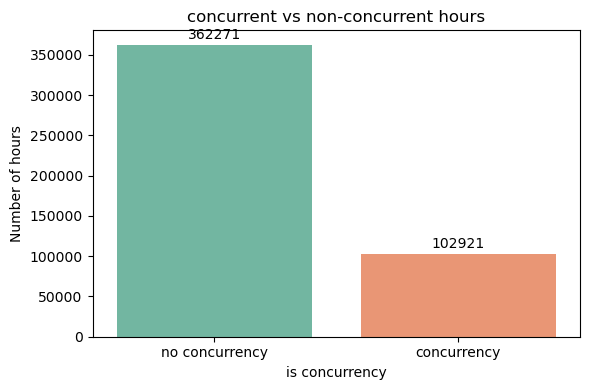

In [4]:
# Plot is_concurrency
import matplotlib.pyplot as plt
import seaborn as sns

# Convert 'cancelled' to boolean for plotting
cancel_bool = df["is_concurrency"].astype(bool)
cancel_counts = cancel_bool.value_counts().sort_index()
labels = ["no concurrency", "concurrency"]

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=cancel_counts.values, palette="Set2")
plt.title("concurrent vs non-concurrent hours")
plt.ylabel("Number of hours")
plt.xlabel("is concurrency")
for i, v in enumerate(cancel_counts.values):
    plt.text(i, v + max(cancel_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

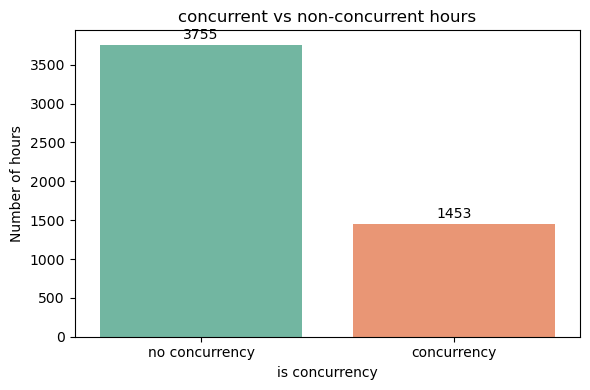

In [5]:
# Plot is_concurrency
import matplotlib.pyplot as plt
import seaborn as sns

# Convert 'cancelled' to boolean for plotting
cancel_bool = df_test["is_concurrency"].astype(bool)
cancel_counts = cancel_bool.value_counts().sort_index()
labels = ["no concurrency", "concurrency"]

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=cancel_counts.values, palette="Set2")
plt.title("concurrent vs non-concurrent hours")
plt.ylabel("Number of hours")
plt.xlabel("is concurrency")
for i, v in enumerate(cancel_counts.values):
    plt.text(i, v + max(cancel_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [6]:
df_processed = df.copy()
# Convert date and time columns to datetime
df_processed["date"] = pd.to_datetime(
    df_processed["date"] + " " + df_processed["hour"].astype(str) + ":00:00"
)
df_processed
# Extract time features from scheduled departure time
df_processed["dep_hour"] = df_processed["date"].dt.hour
df_processed["dep_day_of_week"] = df_processed["date"].dt.dayofweek
df_processed["dep_month"] = df_processed["date"].dt.month
df_processed["dep_day_of_year"] = df_processed["date"].dt.dayofyear

# Extract time features from scheduled arrival time
df_processed["arr_hour"] = df_processed["date"].dt.hour

# Circular encoding for time-based features
print("Creating circular encodings for time-based features...")

# Hour of day (0-23) - circular encoding
df_processed["hour_sin"] = np.sin(2 * np.pi * df_processed["dep_hour"] / 24)
df_processed["hour_cos"] = np.cos(2 * np.pi * df_processed["dep_hour"] / 24)

df_processed["day_of_week_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)
df_processed["day_of_week_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)

df_processed["month_sin"] = np.sin(2 * np.pi * df_processed["dep_month"] / 12)
df_processed["month_cos"] = np.cos(2 * np.pi * df_processed["dep_month"] / 12)

df_processed["day_of_year_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_year"] / 365
)
df_processed["day_of_year_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_year"] / 365
)

print("Circular encodings created successfully!")

df_processed["year"] = df_processed["date"].dt.year
df_processed["airport_group"] = df_processed["airport_group"].fillna("OUT")
df_processed["airport_group"] = df_processed["airport_group"].astype("category")
df_processed["is_concurrency"] = df_processed["is_concurrency"].astype("category")

Creating circular encodings for time-based features...
Circular encodings created successfully!


In [7]:
df_processed_test = df_test.copy()
# Convert date and time columns to datetime
df_processed_test["date"] = pd.to_datetime(
    df_processed_test["date"] + " " + df_processed_test["hour"].astype(str) + ":00:00"
)
# Extract time features from scheduled departure time
df_processed_test["dep_hour"] = df_processed_test["date"].dt.hour
df_processed_test["dep_day_of_week"] = df_processed_test["date"].dt.dayofweek
df_processed_test["dep_month"] = df_processed_test["date"].dt.month
df_processed_test["dep_day_of_year"] = df_processed_test["date"].dt.dayofyear

# Extract time features from scheduled arrival time
df_processed_test["arr_hour"] = df_processed_test["date"].dt.hour

# Circular encoding for time-based features
print("Creating circular encodings for time-based features...")

# Hour of day (0-23) - circular encoding
df_processed_test["hour_sin"] = np.sin(2 * np.pi * df_processed_test["dep_hour"] / 24)
df_processed_test["hour_cos"] = np.cos(2 * np.pi * df_processed_test["dep_hour"] / 24)

df_processed_test["day_of_week_sin"] = np.sin(
    2 * np.pi * df_processed_test["dep_day_of_week"] / 7
)
df_processed_test["day_of_week_cos"] = np.cos(
    2 * np.pi * df_processed_test["dep_day_of_week"] / 7
)

df_processed_test["month_sin"] = np.sin(2 * np.pi * df_processed_test["dep_month"] / 12)
df_processed_test["month_cos"] = np.cos(2 * np.pi * df_processed_test["dep_month"] / 12)

df_processed_test["day_of_year_sin"] = np.sin(
    2 * np.pi * df_processed_test["dep_day_of_year"] / 365
)
df_processed_test["day_of_year_cos"] = np.cos(
    2 * np.pi * df_processed_test["dep_day_of_year"] / 365
)

print("Circular encodings created successfully!")

df_processed_test["year"] = df_processed_test["date"].dt.year
df_processed_test["airport_group"] = df_processed_test["airport_group"].fillna("OUT")
df_processed_test["airport_group"] = df_processed_test["airport_group"].astype("category")
df_processed_test["is_concurrency"] = df_processed_test["is_concurrency"].astype("category")

Creating circular encodings for time-based features...
Circular encodings created successfully!


In [8]:
feature_columns = [
    "airport_group",
    "year",
    "hour_sin",
    "hour_cos",
    "day_of_week_sin",
    "day_of_week_cos",
    "month_sin",
    "month_cos",
    "day_of_year_sin",
    "day_of_year_cos",
    "scheduled_concurrency",
    "scheduled_number_of_flights",
    "scheduled_overlapping_time_minutes",
    "scheduled_is_concurrency",
    # "predicted_concurrency", #Removed for testing
    # "predicted_number_of_flights",
    # "predicted_overlapping_time_minutes",
    # "predicted_is_concurrency",
    "date"
]

print(f"Total features selected: {len(feature_columns)}")


model_data = df_processed[feature_columns + ["is_concurrency"]].copy()
model_data_test = df_processed_test[feature_columns + ["is_concurrency"]].copy()

# Remove rows with missing values in key features
print(f"Modeling dataset shape: {model_data.shape}")

Total features selected: 15
Modeling dataset shape: (465192, 16)


In [9]:
train_df = model_data.copy()
test_df = model_data_test.copy()


# Verify no overlaps between sets
print(f"Train set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")


# Convert to H2O frames
test = h2o.H2OFrame(test_df.drop(["date"], axis=1))
train = h2o.H2OFrame(train_df.drop(["date"], axis=1))

Train set shape: (465192, 16)
Test set shape: (5208, 16)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
████████████████████████████████████████████████████████████████| (done) 100%


In [10]:
# Convert categorical columns back to factors
test["is_concurrency"] = test["is_concurrency"].asfactor()
test["airport_group"] = test["airport_group"].asfactor()
train["is_concurrency"] = train["is_concurrency"].asfactor()
train["airport_group"] = train["airport_group"].asfactor()

print(f"Train set shape: {train.shape}")
print(f"Test set shape: {test.shape}")

# Define predictors and response (excluding date from features)
x = [col for col in feature_columns if col != "date"]
y = "is_concurrency"

print(f"Features (x): {x}")
print(f"Target (y): {y}")

# Verify target is categorical
print(f"Target variable type: {train[y].types}")

# Check class balance in training set
train_target_summary = train[y].table()
print(f"\nClass distribution in training set:")
print(train_target_summary)

# Initialize H2O AutoML with corrected settings for binary classification
print("\nInitializing H2O AutoML for binary classification...")
aml = H2OAutoML(
    max_models=12,
    max_runtime_secs=600,  # 10 minutes
    balance_classes=True,  # Handle class imbalance
    seed=42,
    project_name="concurrency_prediction",
    sort_metric="AUC",  # Now correct for binary classification
    include_algos=["GLM", "GBM", "XGBoost", "DRF", "DeepLearning"], # StackedEnsemble , removed for feature importance
    nfolds=-1,
    stopping_metric="AUC",
    stopping_tolerance=0.01,
    stopping_rounds=3,
    max_after_balance_size=3.0,
)

# Train AutoML models
print("Training AutoML models for binary classification...")
print("This should work now - estimated 3-5 minutes...")
aml.train(x=x, y=y, training_frame=train)

print("\nAutoML training completed!")
print(f"Leaderboard contains {len(aml.leaderboard)} models")

Train set shape: (465192, 15)
Test set shape: (5208, 15)
Features (x): ['airport_group', 'year', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos', 'scheduled_concurrency', 'scheduled_number_of_flights', 'scheduled_overlapping_time_minutes', 'scheduled_is_concurrency']
Target (y): is_concurrency
Target variable type: {'is_concurrency': 'enum'}

Class distribution in training set:
  is_concurrency    Count
               0   362271
               1   102921
[2 rows x 2 columns]


Initializing H2O AutoML for binary classification...
Training AutoML models for binary classification...
This should work now - estimated 3-5 minutes...
AutoML progress: |


16:24:23.520: New models will be added to existing leaderboard concurrency_prediction@@is_concurrency (leaderboard frame=null) with already 14 models.
16:37:26.163: New models will be added to existing leaderboard concurrency_prediction@@is_concurrency (leaderboard frame=null) with already 26 models.
16:40:36.901: New models will be added to existing leaderboard concurrency_prediction@@is_concurrency (leaderboard frame=null) with already 28 models.
17:09:48.346: New models will be added to existing leaderboard concurrency_prediction@@is_concurrency (leaderboard frame=null) with already 40 models.
18:25:19.704: New models will be added to existing leaderboard concurrency_prediction@@is_concurrency (leaderboard frame=null) with already 52 models.

██████████████████████████████████████████████████████████████████████████████████| (done) 100%
████████████████████████████████████████████| (done) 100%

AutoML training completed!
Leaderboard contains 64 models

AutoML training completed!
Le

In [11]:
# View the leaderboard
print("AutoML Leaderboard:")
leaderboard = aml.leaderboard.as_data_frame()
print(leaderboard)

# Get the best model
best_model = aml.leader
print(f"\nBest model: {best_model.model_id}")

# Evaluate on test set
print("\nEvaluating best model on test set...")
test_performance = best_model.model_performance(test)

# Extract metrics properly - H2O returns different formats
try:
    # Try different ways to extract AUC
    auc_value = test_performance.auc()
    if isinstance(auc_value, list) and len(auc_value) > 0:
        auc_value = auc_value[0][0] if isinstance(auc_value[0], list) else auc_value[0]
    print(f"Test AUC: {auc_value:.4f}")
except:
    print("Could not extract AUC")

try:
    # Extract accuracy at different thresholds
    accuracy_data = test_performance.accuracy()
    if isinstance(accuracy_data, list) and len(accuracy_data) > 0:
        # Usually accuracy is reported at optimal threshold
        accuracy_value = (
            accuracy_data[0][1] if len(accuracy_data[0]) > 1 else accuracy_data[0]
        )
        print(f"Test Accuracy: {accuracy_value:.4f}")
    else:
        print(f"Test Accuracy: {accuracy_data:.4f}")
except:
    print("Could not extract Accuracy")

try:
    # Extract precision and recall
    precision_data = test_performance.precision()
    recall_data = test_performance.recall()

    if isinstance(precision_data, list) and len(precision_data) > 0:
        precision_value = (
            precision_data[0][1] if len(precision_data[0]) > 1 else precision_data[0]
        )
        print(f"Test Precision: {precision_value:.4f}")

    if isinstance(recall_data, list) and len(recall_data) > 0:
        recall_value = recall_data[0][1] if len(recall_data[0]) > 1 else recall_data[0]
        print(f"Test Recall: {recall_value:.4f}")

    # Calculate F1 Score from precision and recall
    if "precision_value" in locals() and "recall_value" in locals():
        if precision_value > 0 and recall_value > 0:
            f1_score = (
                2 * (precision_value * recall_value) / (precision_value + recall_value)
            )
            print(f"Test F1-Score: {f1_score:.4f}")
        else:
            print("Test F1-Score: 0.0000 (precision or recall is zero)")
    else:
        print("Could not calculate F1-Score")

except:
    print("Could not extract Precision/Recall")

# Print confusion matrix
print("\nConfusion Matrix:")
try:
    cm = test_performance.confusion_matrix()
    print(cm)
except:
    print("Could not generate confusion matrix")

# Generate predictions on test set
print("\nGenerating predictions on test set...")
predictions = best_model.predict(test)
print("Sample predictions:")
print(predictions.head())

# Feature importance (if available)
try:
    print("\nFeature Importance:")
    importance = best_model.varimp(use_pandas=True)
    print(importance.head(10))
except:
    print("Feature importance not available for this model type")

# Print overall model performance summary
print("\nOverall Model Performance Summary:")
print(test_performance)

AutoML Leaderboard:
                                             model_id       auc   logloss  \
0                     GBM_17_AutoML_8_20250928_182519  0.979253  0.162644   
1                     GBM_12_AutoML_7_20250928_170948  0.979099  0.162717   
2   StackedEnsemble_AllModels_1_AutoML_3_20250928_...  0.978780  0.153524   
3   StackedEnsemble_BestOfFamily_1_AutoML_3_202509...  0.978767  0.153612   
4                      GBM_1_AutoML_3_20250928_160341  0.978640  0.164887   
..                                                ...       ...       ...   
59                     GBM_5_AutoML_4_20250928_162423  0.782985  0.453915   
60                 XGBoost_3_AutoML_4_20250928_162423  0.780081  0.570264   
61            DeepLearning_1_AutoML_4_20250928_162423  0.733303  0.461389   
62                     GLM_2_AutoML_5_20250928_163726  0.557620  0.524869   
63                     GLM_1_AutoML_4_20250928_162423  0.557620  0.524869   

       aucpr  mean_per_class_error      rmse       mse 

In [12]:
# MSE: 0.052547131957420494
# RMSE: 0.229231612037739
# LogLoss: 0.17486170934875206
# AUC: 0.9769405875900268
# AUCPR: 0.9409894391699071
# Gini: 0.9538811751800536
# Null degrees of freedom: 5207
# Residual degrees of freedom: 5202
# Null deviance: 6263.7542049741005
# Residual deviance: 1821.3595645766009
# AIC: 1833.3595645766009

# Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.3657602827004505
#        0     1     Error    Rate
# -----  ----  ----  -------  --------------
# 0      3524  231   0.0615   (231.0/3755.0)
# 1      136   1317  0.0936   (136.0/1453.0)
# Total  3660  1548  0.0705   (367.0/5208.0)

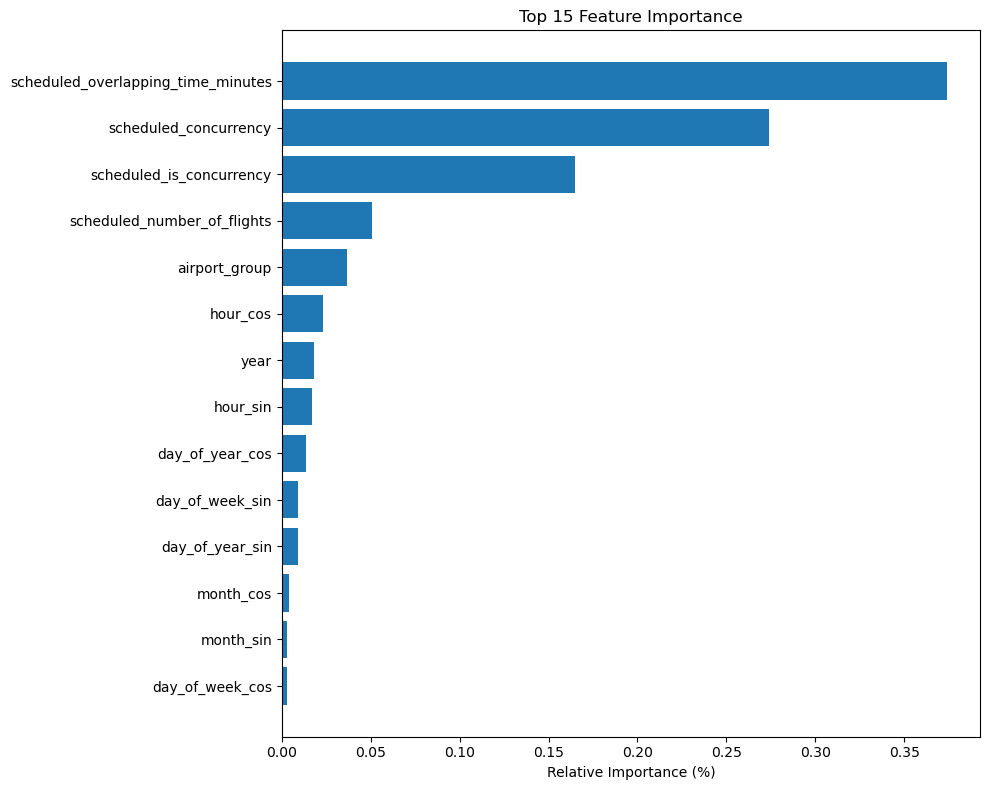

In [13]:
# Plot variable importance
varim = best_model.varimp(use_pandas=True)
plt.figure(figsize=(10, 8))
if len(varim) > 0:
    top_features = varim.head(15)
    plt.barh(range(len(top_features)), top_features["percentage"])
    plt.yticks(range(len(top_features)), top_features["variable"])
    plt.xlabel("Relative Importance (%)")
    plt.title("Top 15 Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No variable importance data available")

In [14]:
print(varim)

                              variable  relative_importance  \
0   scheduled_overlapping_time_minutes        283217.812500   
1                scheduled_concurrency        207388.109375   
2             scheduled_is_concurrency        124875.460938   
3          scheduled_number_of_flights         38630.167969   
4                        airport_group         27592.658203   
5                             hour_cos         17730.066406   
6                                 year         13588.644531   
7                             hour_sin         12951.015625   
8                      day_of_year_cos         10141.787109   
9                      day_of_week_sin          6986.008301   
10                     day_of_year_sin          6883.230469   
11                           month_cos          3122.163818   
12                           month_sin          2295.767334   
13                     day_of_week_cos          2177.468506   

    scaled_importance  percentage  
0            1.000

# Analysis and Potential Improvements

## Current Results Analysis
- **AUC: 0.977** - Excellent performance
- **Key Finding**: Scheduled features outperform predicted features but predicted features still add value
- **Test Setup**: Properly separated test month (October 2024) to avoid data leakage

## Suggested Improvements to Explore

In [15]:
# 1. Feature Engineering Ideas
print("=== Potential New Features to Explore ===")

# Example: Delta features (difference between predicted and scheduled)
print("\n1. Delta Features (Predicted - Scheduled):")
print("   - concurrency_delta = predicted_concurrency - scheduled_concurrency")
print("   - flights_delta = predicted_flights - scheduled_flights") 
print("   - overlap_delta = predicted_overlap - scheduled_overlap")

print("\n2. Ratio Features:")
print("   - concurrency_ratio = predicted_concurrency / (scheduled_concurrency + 1)")
print("   - reliability_score = 1 - abs(predicted - scheduled) / (scheduled + 1)")

print("\n3. Interaction Features:")
print("   - scheduled_concurrency * hour_sin (rush hour effect)")
print("   - airport_group * scheduled_flights (airport-specific patterns)")
print("   - day_of_week * concurrency (weekend/weekday differences)")

print("\n4. Rolling/Lag Features:")
print("   - concurrency in previous hour")
print("   - average concurrency over last 3 hours")
print("   - peak concurrency flag for the day")

print("\n5. Weather Integration:")
print("   - weather conditions affecting actual vs scheduled times")
print("   - visibility, wind conditions at prediction time")

=== Potential New Features to Explore ===

1. Delta Features (Predicted - Scheduled):
   - concurrency_delta = predicted_concurrency - scheduled_concurrency
   - flights_delta = predicted_flights - scheduled_flights
   - overlap_delta = predicted_overlap - scheduled_overlap

2. Ratio Features:
   - concurrency_ratio = predicted_concurrency / (scheduled_concurrency + 1)
   - reliability_score = 1 - abs(predicted - scheduled) / (scheduled + 1)

3. Interaction Features:
   - scheduled_concurrency * hour_sin (rush hour effect)
   - airport_group * scheduled_flights (airport-specific patterns)
   - day_of_week * concurrency (weekend/weekday differences)

4. Rolling/Lag Features:
   - concurrency in previous hour
   - average concurrency over last 3 hours
   - peak concurrency flag for the day

5. Weather Integration:
   - weather conditions affecting actual vs scheduled times
   - visibility, wind conditions at prediction time


In [16]:
# 2. Quick Implementation of Delta Features
print("=== Implementing Delta Features ===")

# Let's add some delta features to see if they improve performance
def add_delta_features(df_input):
    df_enhanced = df_input.copy()
    
    # Delta features (predicted - scheduled)
    df_enhanced['concurrency_delta'] = df_enhanced['predicted_concurrency'] - df_enhanced['scheduled_concurrency']
    df_enhanced['flights_delta'] = df_enhanced['predicted_number_of_flights'] - df_enhanced['scheduled_number_of_flights']
    df_enhanced['overlap_delta'] = df_enhanced['predicted_overlapping_time_minutes'] - df_enhanced['scheduled_overlapping_time_minutes']
    
    # Ratio features 
    df_enhanced['concurrency_ratio'] = df_enhanced['predicted_concurrency'] / (df_enhanced['scheduled_concurrency'] + 1)
    df_enhanced['flights_ratio'] = df_enhanced['predicted_number_of_flights'] / (df_enhanced['scheduled_number_of_flights'] + 1)
    
    # Reliability score (how close predicted is to scheduled)
    df_enhanced['concurrency_reliability'] = 1 - np.abs(df_enhanced['concurrency_delta']) / (df_enhanced['scheduled_concurrency'] + 1)
    
    # Interaction features
    df_enhanced['scheduled_concurrency_x_hour_sin'] = df_enhanced['scheduled_concurrency'] * df_enhanced['hour_sin']
    df_enhanced['scheduled_concurrency_x_hour_cos'] = df_enhanced['scheduled_concurrency'] * df_enhanced['hour_cos']
    
    return df_enhanced

# Test on a small sample first
sample_data = model_data.head(1000)
enhanced_sample = add_delta_features(sample_data)

print(f"Original features: {len(sample_data.columns)}")
print(f"Enhanced features: {len(enhanced_sample.columns)}")
print(f"New features added: {len(enhanced_sample.columns) - len(sample_data.columns)}")

# Show new features
new_features = [col for col in enhanced_sample.columns if col not in sample_data.columns]
print(f"New features: {new_features}")

# Check for any issues
print(f"Any NaN values in new features: {enhanced_sample[new_features].isnull().any().any()}")
print(f"Any infinite values: {np.isinf(enhanced_sample[new_features].select_dtypes(include=[np.number])).any().any()}")

=== Implementing Delta Features ===


KeyError: 'predicted_concurrency'

In [ ]:
# 3. Model Interpretation and Validation Ideas
print("=== Model Validation and Interpretation Suggestions ===")

print("\n🔍 DEEPER ANALYSIS OPPORTUNITIES:")
print("1. **Temporal Validation**: Test on different months/seasons")
print("   - Your October test is great, but try Q1 vs Q4 performance")
print("   - Holiday periods vs normal periods")

print("\n2. **Airport-Specific Analysis**:")
print("   - Model performance by airport group")
print("   - Some airports might benefit more from predicted features")

print("\n3. **Error Analysis**:")
print("   - When does the model fail? (False positives vs false negatives)")
print("   - Are errors clustered around specific times/airports?")

print("\n4. **Threshold Optimization**:")
print("   - Your current threshold might not be optimal for operations")
print("   - Consider cost of false positives vs false negatives")

print("\n🎯 BUSINESS VALUE ASSESSMENT:")
print("1. **Actionability**: Can operations actually use these predictions?")
print("2. **Lead Time**: How far in advance can you predict reliably?")
print("3. **Cost-Benefit**: What's the operational value of 97.7% vs 91.4% AUC?")

print("\n📊 FEATURE ENGINEERING PRIORITIES:")
print("Based on your variable importance, focus on:")
print("- Enhancing scheduled_is_concurrency feature (your top performer)")
print("- Better overlap time calculations") 
print("- Airport-specific features (currently only 3.3% importance)")

=== Model Validation and Interpretation Suggestions ===

🔍 DEEPER ANALYSIS OPPORTUNITIES:
1. **Temporal Validation**: Test on different months/seasons
   - Your October test is great, but try Q1 vs Q4 performance
   - Holiday periods vs normal periods

2. **Airport-Specific Analysis**:
   - Model performance by airport group
   - Some airports might benefit more from predicted features

3. **Error Analysis**:
   - When does the model fail? (False positives vs false negatives)
   - Are errors clustered around specific times/airports?

4. **Threshold Optimization**:
   - Your current threshold might not be optimal for operations
   - Consider cost of false positives vs false negatives

🎯 BUSINESS VALUE ASSESSMENT:
1. **Actionability**: Can operations actually use these predictions?
2. **Lead Time**: How far in advance can you predict reliably?
3. **Cost-Benefit**: What's the operational value of 97.7% vs 91.4% AUC?

📊 FEATURE ENGINEERING PRIORITIES:
Based on your variable importance, foc